In [1]:
import pandas as pd
import numpy as np

student_df = pd.read_csv('../data/raw/student_mental_health.csv')


In [2]:
print("Aperçu des premières lignes :")
display(student_df.head())

print(f"\nDimensions du dataset : {student_df.shape[0]} lignes et {student_df.shape[1]} colonnes\n")
student_df.info()

Aperçu des premières lignes :


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium



Dimensions du dataset : 2000 lignes et 17 colonnes

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float

In [3]:
missing_count = student_df.isna().sum()
missing_pct = (missing_count / len(student_df)) * 100

missing_df = pd.DataFrame({
    'Valeurs manquantes': missing_count,
    'Pourcentage (%)': missing_pct.round(2)
})

print("Colonnes avec des valeurs manquantes :")
print(missing_df[missing_df['Valeurs manquantes'] > 0].sort_values(by='Valeurs manquantes', ascending=False))

print(f"\nNombre de lignes dupliquées : {student_df.duplicated().sum()}")

Colonnes avec des valeurs manquantes :
                    Valeurs manquantes  Pourcentage (%)
Financial_Stress                    91             4.55
Diet_Quality                        69             3.45
Sleep_Hours                         62             3.10
Social_Media_Hours                  58             2.90
Family_Support                      54             2.70
Attendance_Rate                     47             2.35
GPA                                 38             1.90

Nombre de lignes dupliquées : 0


In [4]:
print("statistique des variables :")
display(student_df.describe(include="number").T)

statistique des variables :


,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [ ]:
anomalies = {
    'Âge (<15 ou >40)': ((student_df['Age'] < 15) | (student_df['Age'] > 40)).sum(),
    'Sommeil (<0 ou >24h)': ((student_df['Sleep_Hours'] < 0) | (student_df['Sleep_Hours'] > 24)).sum(),
    'GPA (<0 ou >4)': ((student_df['GPA'] < 0) | (student_df['GPA'] > 4)).sum(),
    'Assiduité (<0 ou >100%)': ((student_df['Attendance_Rate'] < 0) | (student_df['Attendance_Rate'] > 100)).sum(),
    'Réseaux > Écran': (student_df['Social_Media_Hours'] > student_df['Screen_Time_Hours']).sum()
}

for k, v in anomalies.items():
    print(f"{k}: {v}")

student_df = student_df[(student_df['Social_Media_Hours'] <= student_df['Screen_Time_Hours']) | (student_df['Social_Media_Hours'].isna())].copy()

Âge (<15 ou >40): 0
Sommeil (<0 ou >24h): 0
GPA (<0 ou >4): 0
Assiduité (<0 ou >100%): 0
Réseaux > Écran: 37


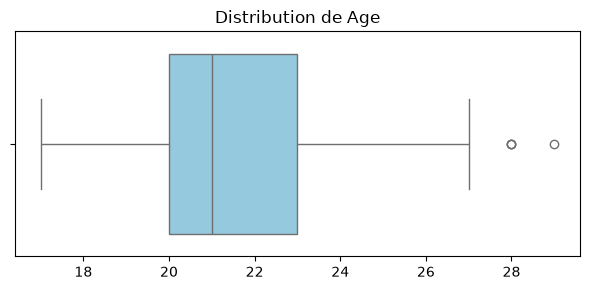

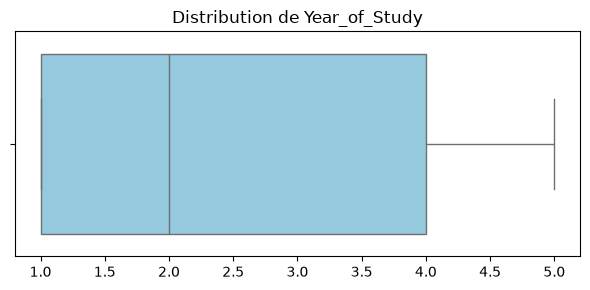

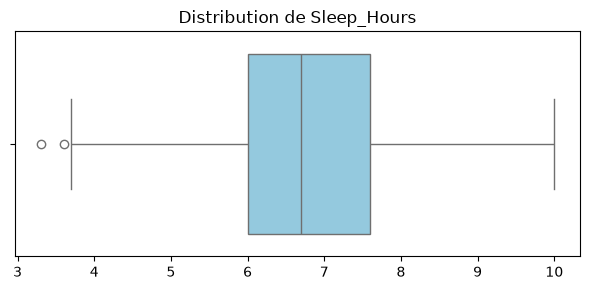

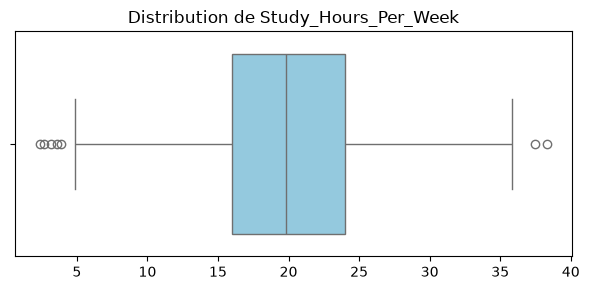

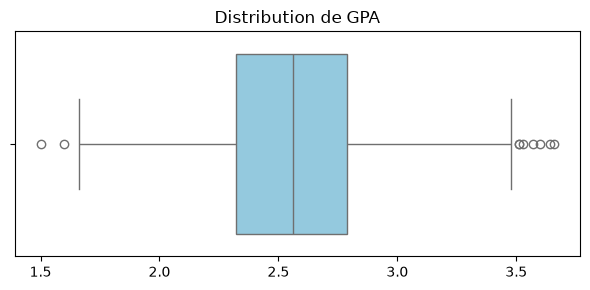

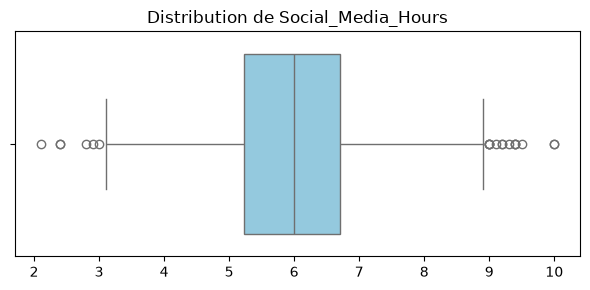

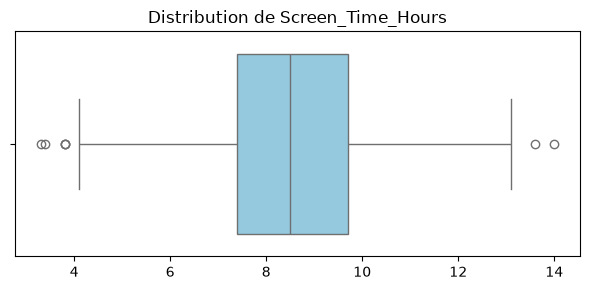

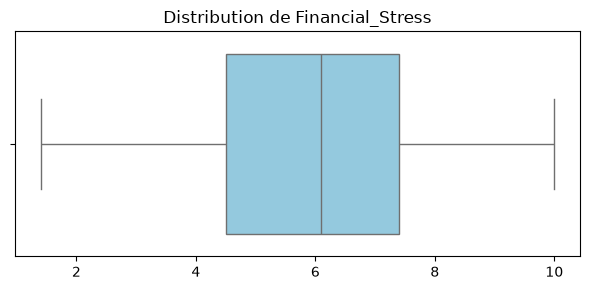

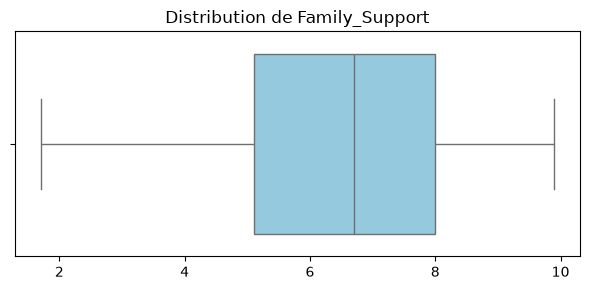

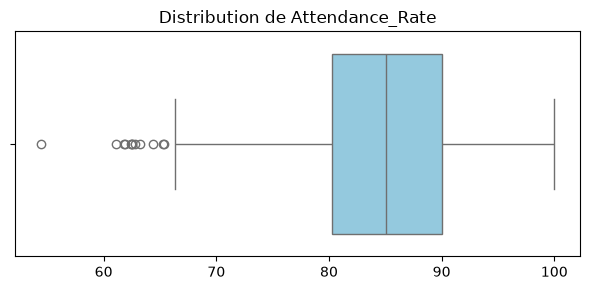

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = student_df.select_dtypes(include="number").columns

for col in num_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=student_df[col], color='skyblue')
    plt.title(f"Distribution de {col}")
    plt.xlabel("")
    plt.tight_layout()
    plt.show()

In [17]:
# 6. Détection et affichage synthétique des outliers par IQR
outliers_summary = []

for col in num_cols:
    Q1 = student_df[col].quantile(0.25)
    Q3 = student_df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = student_df[(student_df[col] < lower_bound) | (student_df[col] > upper_bound)][col]
    
    outliers_summary.append({
        'Variable': col,
        'Borne Inf (Lower)': round(lower_bound, 2),
        'Borne Sup (Upper)': round(upper_bound, 2),
        'Nombre Outliers': len(outliers),
        'Valeurs Extrêmes': sorted(outliers.tolist())
    })

display(pd.DataFrame(outliers_summary))


,Variable,Borne Inf (Lower),Borne Sup (Upper),Nombre Outliers,Valeurs Extrêmes
0,Age,15.50,27.50,4,"[28, 28, 28, 29]"
1,Year_of_Study,-3.50,8.50,0,[]
2,Sleep_Hours,3.60,10.00,2,"[3.3, 3.6]"
3,Study_Hours_Per_Week,4.00,36.00,7,"[2.4, 2.7, 3.2, 3.6, 3.9, 37.5, 38.3]"
4,GPA,1.61,3.50,9,"[1.5, 1.6, 3.51, 3.51, 3.53, 3.57, 3.6, 3.64, ..."
5,Social_Media_Hours,3.01,8.91,20,"[2.1, 2.4, 2.4, 2.8, 2.9, 3.0, 9.0, 9.0, 9.0, ..."
6,Screen_Time_Hours,3.95,13.15,7,"[3.3, 3.4, 3.8, 3.8, 3.8, 13.6, 14.0]"
7,Financial_Stress,0.15,11.75,0,[]
8,Family_Support,0.75,12.35,0,[]
9,Attendance_Rate,65.75,104.55,12,"[54.4, 61.1, 61.8, 61.9, 62.4, 62.5, 62.5, 62...."


In [8]:
num_stats = student_df[num_cols].describe().T
num_stats['median'] = student_df[num_cols].median()
num_stats = num_stats[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max']]

print("Statistiques des variables numériques (après nettoyage) :")
display(num_stats)

cat_cols = student_df.select_dtypes(exclude=['number']).columns
print("\nStatistiques des variables catégorielles :")
display(student_df[cat_cols].describe().T)

Statistiques des variables numériques (après nettoyage) :


,count,mean,std,min,25%,median,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00



Statistiques des variables catégorielles :


,count,unique,top,freq
Student_ID,2000,2000,STU0001,1
Gender,2000,3,Female,971
Physical_Activity,2000,3,Moderate,906
Part_Time_Job,2000,2,No,1289
Diet_Quality,1931,3,Average,860
Previous_Mental_Health_History,2000,2,No,1408
Mental_Health_Risk,2000,3,High,680


Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


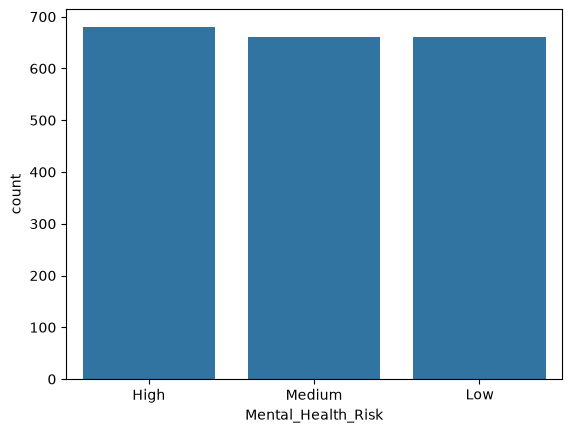

In [9]:
print(student_df['Mental_Health_Risk'].value_counts())

sns.countplot(data=student_df, x='Mental_Health_Risk')
plt.show()


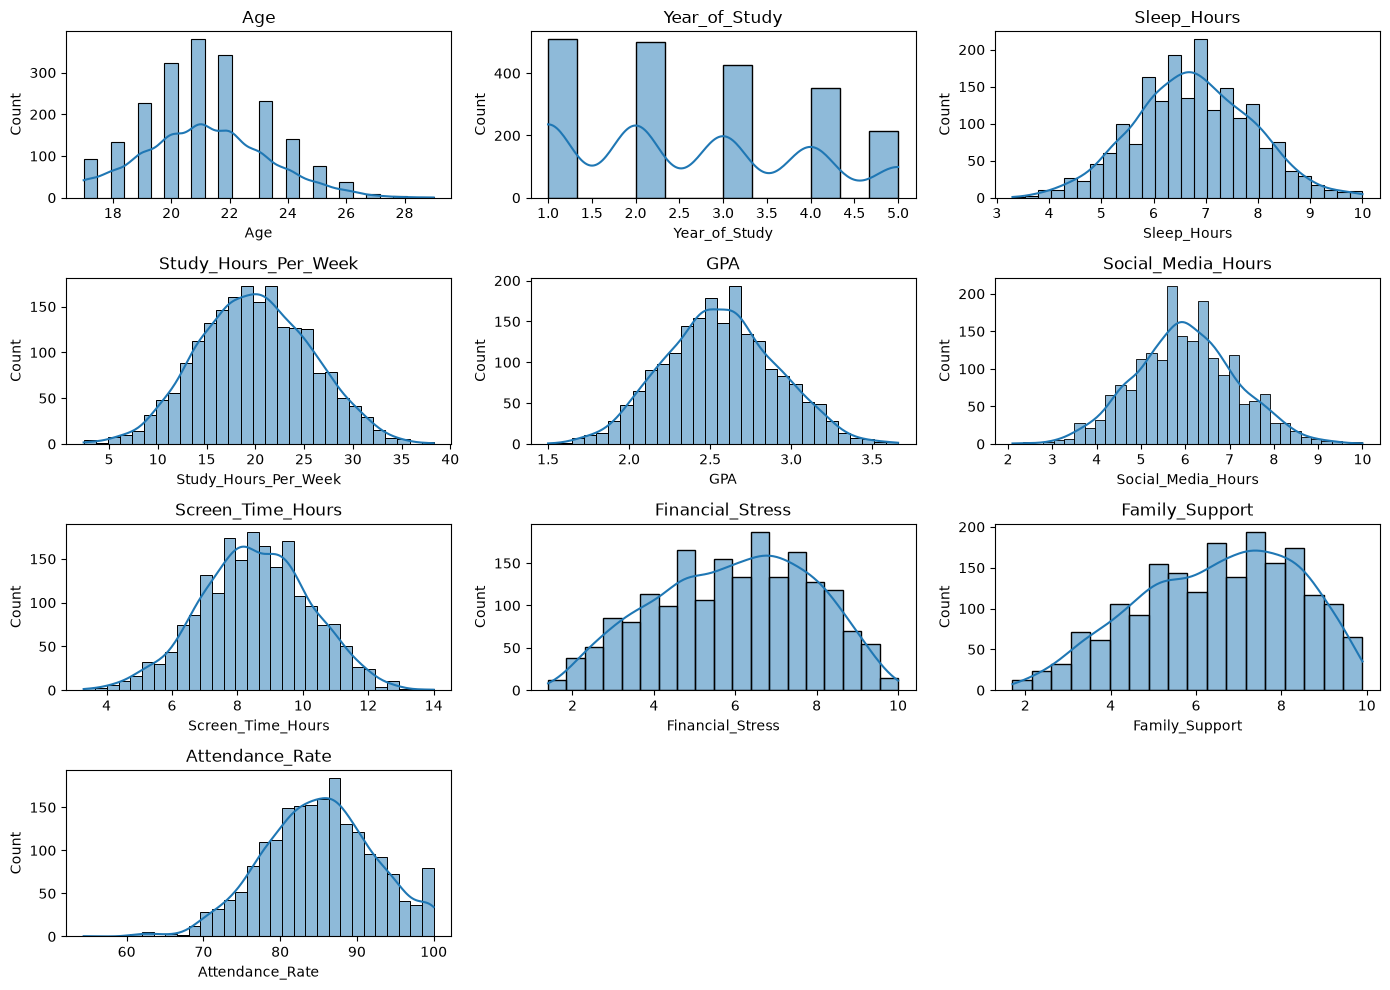

In [10]:
plt.figure(figsize=(14, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(4, 3, i)
    sns.histplot(student_df[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

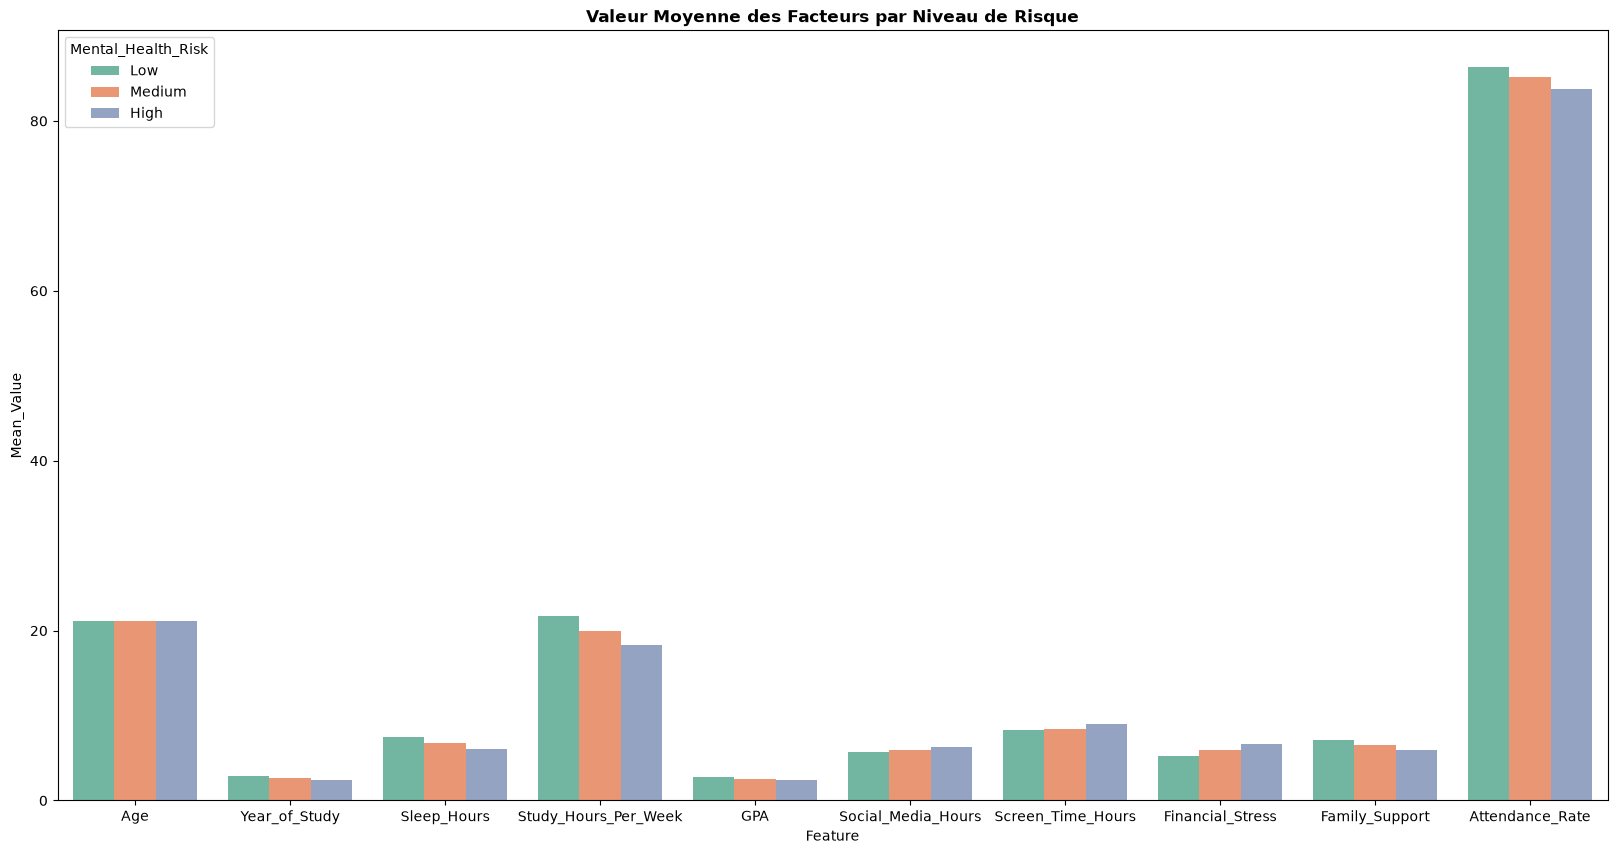

In [11]:
mean_df = student_df.groupby('Mental_Health_Risk')[num_cols].mean().loc[['Low', 'Medium', 'High']].reset_index()
melted_mean = pd.melt(mean_df, id_vars=['Mental_Health_Risk'], var_name='Feature', value_name='Mean_Value')

# Barplot groupé
plt.figure(figsize=(20, 10))
sns.barplot(data=melted_mean, x='Feature', y='Mean_Value', hue='Mental_Health_Risk', palette='Set2')
plt.title('Valeur Moyenne des Facteurs par Niveau de Risque', fontsize=12, fontweight='bold')
plt.show()

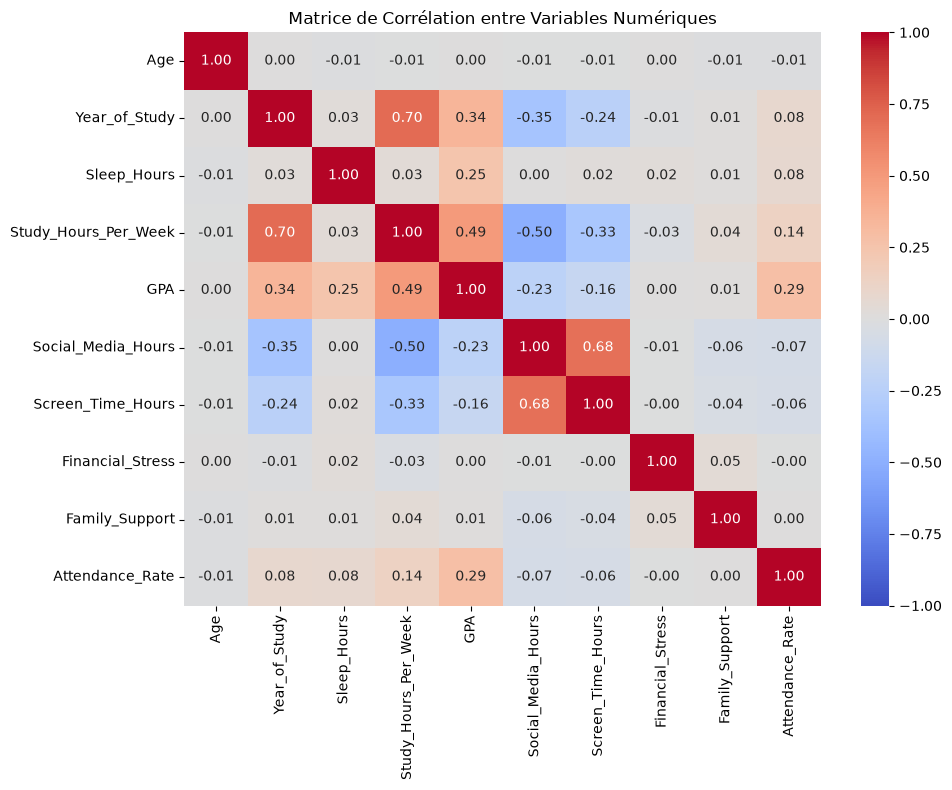

In [12]:
corr = student_df[num_cols].corr()

# 2. Affichage du Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de Corrélation entre Variables Numériques")
plt.tight_layout()
plt.show()

In [13]:
student_df['Risk_Encoded'] = student_df['Mental_Health_Risk'].map({'Low': 0, 'Medium': 1, 'High': 2})

# 2. Corrélation avec le risque
print(student_df.select_dtypes(include='number').corr()['Risk_Encoded'])

Age                     0.004961
Year_of_Study          -0.166404
Sleep_Hours            -0.541857
Study_Hours_Per_Week   -0.238793
GPA                    -0.352626
Social_Media_Hours      0.207601
Screen_Time_Hours       0.173972
Financial_Stress        0.313547
Family_Support         -0.250894
Attendance_Rate        -0.145362
Risk_Encoded            1.000000
Name: Risk_Encoded, dtype: float64
